# Tutorial 8 — Catastrophic forgetting in the Hopfield model

Notebook of the programming section of chapter 8 of R. Kühn, P. Vivo and F. Zamponi,
*Introduction to statistical physics for non-physicists* (Oxford University Press).

**How to run it.** Run all cells from top to bottom, locally (Jupyter, with the package `opencv-python`)
or on Google Colab: [open it in Colab](https://colab.research.google.com/github/francescozamponi/statphys-tutorials/blob/main/Tutorial_8/Tutorial_8.ipynb).
The images are downloaded automatically if needed.

**The images.** The patterns are the 80 images of cats `1.jpg` ... `80.jpg` of the folder `PetImages/Cat`
of the *Cats and Dogs Dataset* (Asirra dataset of Microsoft Research and Petfinder.com),
distributed by [Microsoft](https://www.microsoft.com/en-us/download/details.aspx?id=54765) under the Community Data License Agreement –
Permissive 2.0, whose text is in `cats/CDLA-Permissive-2.0.pdf`.

The random number generator is seeded, so that the notebook reproduces the figures of the book.

In [2]:
import logging
logging.getLogger('fontTools').setLevel(logging.ERROR)

import numpy as np
import math
import matplotlib.pyplot as plt
import cv2
import os, sys, zipfile, urllib.request
%matplotlib inline

IN_COLAB = 'google.colab' in sys.modules
BOOK_REPO = 'https://raw.githubusercontent.com/francescozamponi/statphys-tutorials/main/'

# Book formatting: every figure is saved at its printed size, so that all text prints at the
# same size in the book (bookfig.py; it does not change the plots). Without bookfig.py the
# figures are saved as they are.
sys.path[:0] = ['..', '../Figs_generator']
try:
    from bookfig import setup, save, HALF, SINGLE, FULL
except ImportError:                         # e.g. on Colab: fetch bookfig.py from the book repository
    try:
        urllib.request.urlretrieve(BOOK_REPO + 'bookfig.py', 'bookfig.py')
        from bookfig import setup, save, HALF, SINGLE, FULL
    except Exception:
        setup = None
if setup:
    setup()
else:
    HALF, SINGLE, FULL = 0.49, 0.7, 1.0
    def save(path, width, **kw):
        plt.savefig(path, bbox_inches='tight')

## Get the images

The patterns $\xi^1, \dots, \xi^{80}$ are the images `1.jpg` ... `80.jpg`, kept in the folder `cats/`.
They are taken from the first of these sources that works:
1. the folder `cats/`, if they are already there;
2. the book repository;
3. Microsoft: the zip file of the dataset (about 790 MB) is downloaded, the images `1.jpg` ... `80.jpg`
   of the folder `PetImages/Cat` and the licence are extracted from it, and the zip file is deleted;
4. on Colab, as a last resort, you are asked to upload the images.

The folder also keeps the licence of the images, `CDLA-Permissive-2.0.pdf`, and a `README.md` with their
attribution, which is written by the cell below if it is missing.

In [4]:
path = 'cats/'
NEEDED = [f'{k}.jpg' for k in range(1, 81)]
LICENCE = 'CDLA-Permissive-2.0.pdf'
MICROSOFT_ZIP = 'https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip'

def missing():
    return [f for f in NEEDED if not os.path.exists(path + f)]

os.makedirs(path, exist_ok=True)
if missing():                                       # 2. book repository
    try:
        for f in missing() + [LICENCE]:
            urllib.request.urlretrieve(BOOK_REPO + 'Tutorial_8/' + path + f, path + f)
        print('images downloaded from the book repository')
    except Exception as e:
        print('book repository:', e)
if missing():                                       # 3. Microsoft
    zname = 'kagglecatsanddogs_5340.zip'
    try:
        print('downloading the Cats and Dogs dataset from Microsoft (about 790 MB)...')
        urllib.request.urlretrieve(MICROSOFT_ZIP, zname)
        with zipfile.ZipFile(zname) as z:
            names = z.namelist()
            for f in missing():
                member = [m for m in names if m.endswith('PetImages/Cat/' + f)][0]
                with open(path + f, 'wb') as out:
                    out.write(z.read(member))
            # the licence of the dataset (Community Data License Agreement), kept with the images
            lic = [m for m in names if os.path.basename(m).upper().startswith('CDLA') and m.lower().endswith('.pdf')]
            if lic:
                with open(path + LICENCE, 'wb') as out:
                    out.write(z.read(lic[0]))
            else:
                print('Warning: licence file not found in the zip; see', 'https://www.microsoft.com/en-us/download/details.aspx?id=54765')
        print('images and licence extracted from the Microsoft zip file')
    except Exception as e:
        print('Microsoft:', e)
    finally:
        if os.path.exists(zname):
            os.remove(zname)
if missing() and IN_COLAB:                          # 4. upload
    from google.colab import files
    print('Please upload the images', ', '.join(missing()))
    for name in files.upload():
        os.replace(name, path + name)
if missing():
    raise FileNotFoundError(f'{len(missing())} images missing, e.g. {missing()[0]}: see the instructions above')

# the attribution of the images and the licence, kept with them
README = """# Cat images

The images `1.jpg` ... `80.jpg` are the images of the same name in the folder `PetImages/Cat` of the
*Cats and Dogs Dataset* (Asirra dataset of Microsoft Research and Petfinder.com), distributed by
Microsoft at https://www.microsoft.com/en-us/download/details.aspx?id=54765
(file `kagglecatsanddogs_5340.zip`) under the Community Data License Agreement - Permissive -
Version 2.0, whose text is in `CDLA-Permissive-2.0.pdf`. The images are shared unmodified.
"""
if not os.path.exists(path + 'README.md'):
    with open(path + 'README.md', 'w') as f:
        f.write(README)
if not os.path.exists(path + LICENCE):
    print('Warning: the licence', LICENCE, 'is missing; it is in the zip file of the dataset, see',
          'https://www.microsoft.com/en-us/download/details.aspx?id=54765')
print(len(NEEDED), 'images in', path)

80 images in cats/


# One Memory

We use the images of cats of the dataset described at the top of the notebook.

<Figure size 336.955x252.717 with 0 Axes>

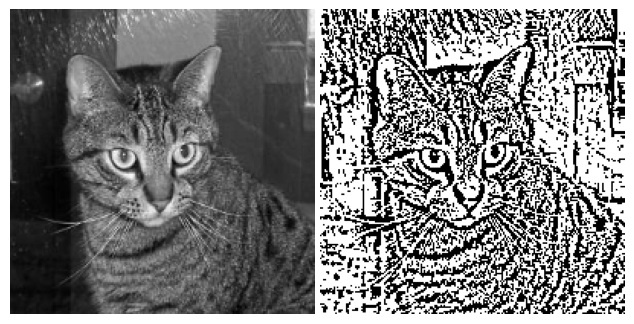

In [6]:
L=200
N=L*L

# read the image file
img = cv2.imread(path+'1.jpg', 2)
img = cv2.resize(img, (L,L) , interpolation=cv2.INTER_LINEAR)

# converting to its binary form in [0,255]
bw = cv2.adaptiveThreshold(img,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,cv2.THRESH_BINARY,11,2)

plt.gray()
fig, ((ax0, ax1)) = plt.subplots(nrows=1, ncols=2, figsize=(12,6))
ax0.imshow(img)
ax0.axis("off")
ax1.imshow(bw)
ax1.axis("off")

plt.tight_layout()
save('cat_binary.pdf', 0.9)
plt.show()

In [7]:
def tovector(image):
  v = image.flatten()
  v = v/255*2 - 1
  return np.array(v)

def toimage(v):
  return (1+v.reshape((L,L)))/2*255

def imagedot(a, b):
  return np.dot(tovector(a),tovector(b))/N

In [8]:
# (1+tanh(beta*x))/2 = exp(beta*x)/(2 cosh(beta*x)), written so that it never exceeds 1 by rounding
# both init and pattern are given in [0,255] format and converted internally
def Hopfield_iter(init, pattern, beta, steps):
  xiH = tovector(pattern)
  mt=[]
  St = tovector(init)
  for t in range(steps):
    m=np.dot(xiH,St)/N
    mt.append(m)
    pp=(1+np.tanh(beta*m))/2
    p=np.array([1-pp,pp]).flatten()
    St=np.random.choice([-1,1], N, p=p)
    St=St*xiH
  return mt,toimage(St)

In [9]:
np.random.seed(0)   # fixed seed: reproduces the run shown in the book
bw0 = np.random.choice([0,255], (L,L))
print('init',imagedot(bw0,bw))

betas=[0.8,1,1.5,4]
m={}
for beta in betas:
    m[beta], bwE = Hopfield_iter(bw0,bw,beta,100)
    print(beta,imagedot(bw0,bw),imagedot(bwE,bw))

init 0.00705
0.8 0.00705 -0.0002
1 0.00705 0.04945
1.5 0.00705 0.86025
4 0.00705 0.9993


<Figure size 336.955x252.717 with 0 Axes>

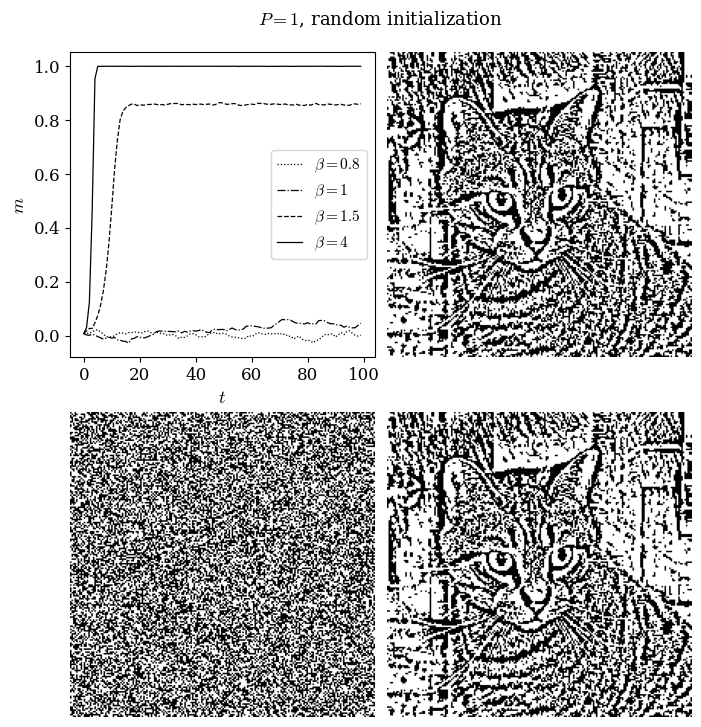

In [10]:
plt.gray()
fig, ((ax0, ax1), (ax2, ax3)) = plt.subplots(nrows=2, ncols=2, figsize=(12,12))
fig.suptitle('$P=1$, random initialization')

for i, beta in enumerate(betas):
    ax0.plot(
        m[beta],
        label=rf'$\beta={beta}$',
        linestyle=[':', '-.', '--', '-'][i % 4],
        color='black'
    )
ax0.set_xlabel('$t$')
ax0.set_ylabel('$m$')
ax0.legend(loc='center right')
ax0.set_box_aspect(1)   # square plot, as the images
ax1.imshow(bw)
ax1.axis("off")
ax2.imshow(bw0)
ax2.axis("off")
ax3.imshow(bwE)
ax3.axis("off")

plt.tight_layout()
save('P1_random.pdf', FULL)
plt.show()

In [11]:
np.random.seed(0)   # fixed seed: reproduces the run shown in the book
bw0 = np.random.choice([0,255], (L,L))
for i in range(int(L/2)):
  for j in range(int(L/2)):
    bw0[i,j]=bw[i,j]

print('init',imagedot(bw0,bw))

betas=[0.8,1,1.5,4]
m={}
for beta in betas:
    m[beta], bwE = Hopfield_iter(bw0,bw,beta,100)
    print(beta,imagedot(bw0,bw),imagedot(bwE,bw))


init 0.25415
0.8 0.25415 -0.0002
1 0.25415 0.12915
1.5 0.25415 0.86025
4 0.25415 0.9993


<Figure size 336.955x252.717 with 0 Axes>

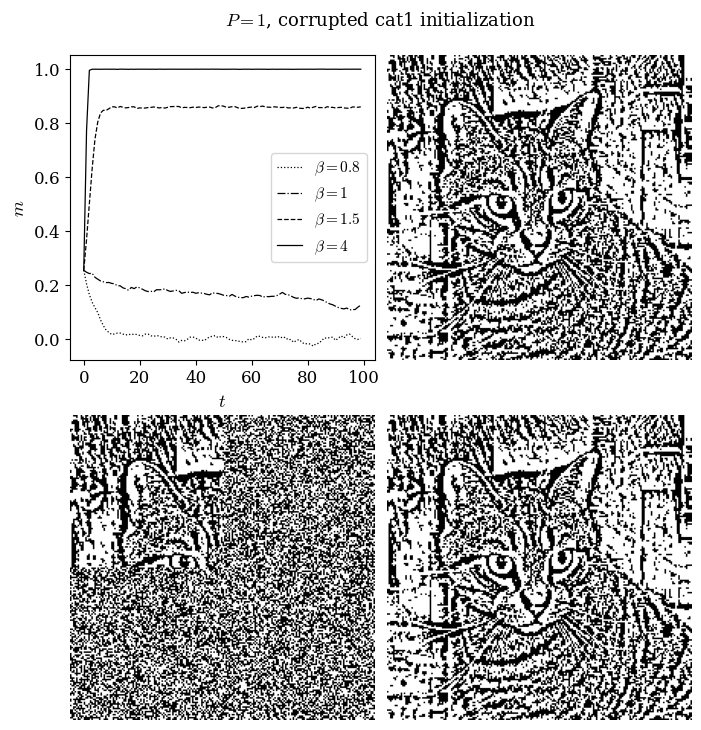

In [12]:
plt.gray()
fig, ((ax0, ax1), (ax2, ax3)) = plt.subplots(nrows=2, ncols=2, figsize=(12,12))
fig.suptitle('$P=1$, corrupted cat1 initialization')

for i, beta in enumerate(betas):
    ax0.plot(
        m[beta],
        label=rf'$\beta={beta}$',
        linestyle=[':', '-.', '--', '-'][i % 4],
        color='black'
    )
ax0.set_xlabel('$t$')
ax0.set_ylabel('$m$')
ax0.legend(loc='center right')
ax0.set_box_aspect(1)   # square plot, as the images
ax1.imshow(bw)
ax1.axis("off")
ax2.imshow(bw0)
ax2.axis("off")
ax3.imshow(bwE)
ax3.axis("off")

plt.tight_layout()
save('P1_corrupted.pdf', FULL)
plt.show()

# Many Memories

We use the images of cats of the dataset described at the top of the notebook.

In [14]:
Ndata=len(NEEDED)
bw = []
# read the image files 1.jpg ... 80.jpg
for f in NEEDED:
  img = cv2.imread(path+f, 2)
  img = cv2.resize(img, (L,L) , interpolation=cv2.INTER_LINEAR)
  bw.append( cv2.adaptiveThreshold(img,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,cv2.THRESH_BINARY,11,2) )

mean m_mu: 0.286304375   range: 0.00775 0.71415   mean q_munu (mu<nu): 0.08620321202531646


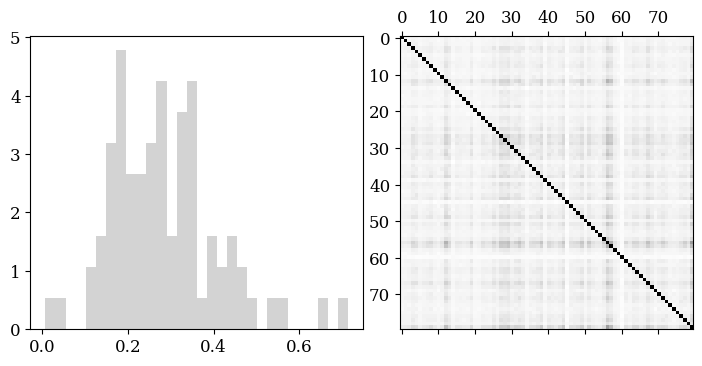

In [15]:
mdata=[tovector(x).sum()/N for x in bw]
q=np.zeros((Ndata,Ndata))
for i in range(Ndata):
  for j in range(Ndata):
    q[i,j]=imagedot(bw[i],bw[j])

fig, ((ax0, ax1)) = plt.subplots(nrows=1, ncols=2, figsize=(24,12))
ax0.hist(mdata, bins=30, facecolor='lightgrey',density=True)   # magnetisations m_mu of the 80 patterns
print('mean m_mu:', np.mean(mdata), '  range:', np.min(mdata), np.max(mdata), '  mean q_munu (mu<nu):', q[np.triu_indices(Ndata,1)].mean())
ax1.matshow(q, cmap=plt.cm.Greys)

plt.tight_layout()
save('pattern_overlaps.pdf', FULL)
plt.show()

<Figure size 336.955x252.717 with 0 Axes>

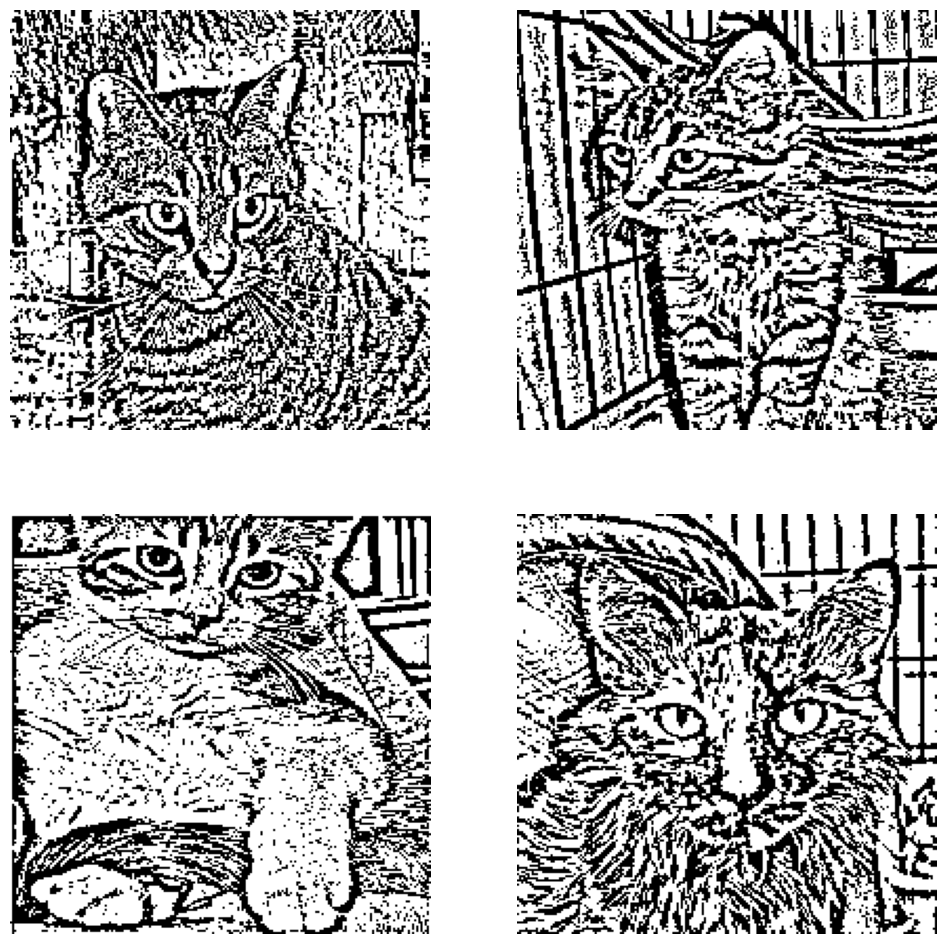

In [16]:
plt.gray()
fig, ((ax0, ax1), (ax2, ax3)) = plt.subplots(nrows=2, ncols=2, figsize=(12,12))
ax0.imshow(bw[0])
ax0.axis("off")
ax1.imshow(bw[1])
ax1.axis("off")
ax2.imshow(bw[8])
ax2.axis("off")
ax3.imshow(bw[9])
ax3.axis("off")
plt.show()

In [17]:
# (1+tanh(beta*x))/2 = exp(beta*x)/(2 cosh(beta*x)), written so that it never exceeds 1 by rounding
# both init and pattern are given in [0,255] format and converted internally
def Hopfield_iter(init, patterns, beta, steps):
  xiH = np.array([tovector(x) for x in patterns])
  mt=[]
  St = tovector(init)
  for t in range(steps):
    m=np.array([np.dot(x,St)/N for x in xiH])
    mt.append(m)
    phi=np.dot(m,xiH)
    pp=np.array([(1+np.tanh(beta*x))/2 for x in phi])
    St=np.array([np.random.choice([-1,1], p=[1-x,x]) for x in pp])
  return np.array(mt),toimage(St)

In [18]:
np.random.seed(14)   # fixed seed: reproduces the run shown in the book
P=4
beta=4
T=20
bwP = bw[0:P]
bw0 = np.random.choice([0,255], (L,L))

m, bwE = Hopfield_iter(bw0,bwP,beta,T)

print([imagedot(bw0,x) for x in bwP])
print([imagedot(bwE,x) for x in bwP])

[-0.00145, -0.00425, -0.00315, 0.0067]
[0.0528, 0.0723, 0.0744, 0.99925]


<Figure size 336.955x252.717 with 0 Axes>

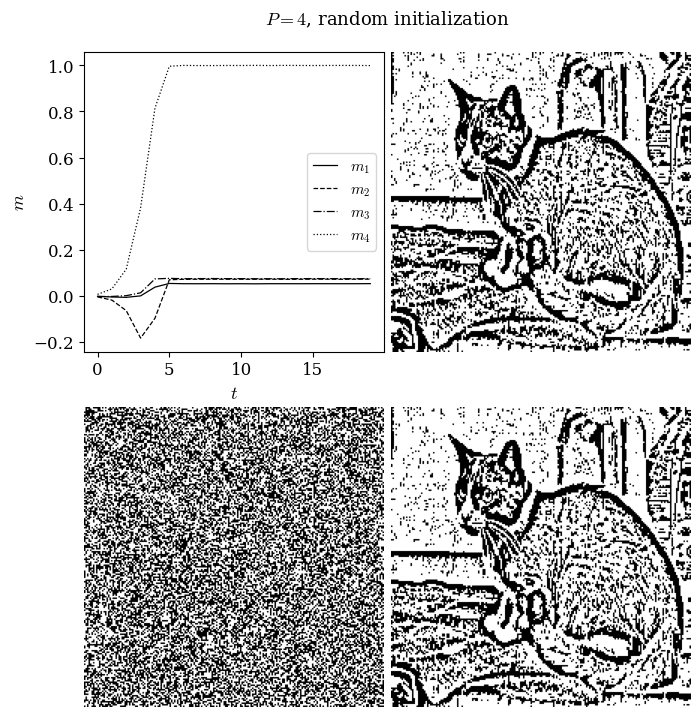

In [19]:
linestyles = ['-', '--', '-.', ':', (0, (1,1)), (0, (5,1)), (0, (3,1,1,1)), (0, (5,2,1,2))]

plt.gray()
fig, ((ax0, ax1), (ax2, ax3)) = plt.subplots(nrows=2, ncols=2, figsize=(12,12))
fig.suptitle('$P=4$, random initialization')

for i in range(P):
  ax0.plot(m[:,i],label=rf'$m_{i+1}$',color='black',linestyle=linestyles[i % len(linestyles)])
ax0.set_xlabel('$t$')
ax0.set_ylabel('$m$')
ax0.legend(loc='center right')
ax0.set_box_aspect(1)   # square plot, as the images
ax1.imshow(bw[np.argmax(np.abs(m[-1]))])
ax1.axis("off")
ax2.imshow(bw0)
ax2.axis("off")
ax3.imshow(bwE)
ax3.axis("off")

plt.tight_layout()
save('P4_random.pdf', FULL)
plt.show()

In [20]:
np.random.seed(0)   # fixed seed: reproduces the run shown in the book
P=4
beta=4
index=0
T=20
bwP = bw[0:P]
bw0 = np.random.choice([0,255], (L,L))
for i in range(int(L/2)):
  for j in range(int(L/2)):
    bw0[i,j]=bw[index][i,j]


m, bwE = Hopfield_iter(bw0,bwP,beta,T)

print([imagedot(bw0,x) for x in bwP])
print([imagedot(bwE,x) for x in bwP])

[0.25415, 0.00035, 0.00075, 0.0166]
[0.999, 0.0257, 0.0313, 0.05285]


<Figure size 336.955x252.717 with 0 Axes>

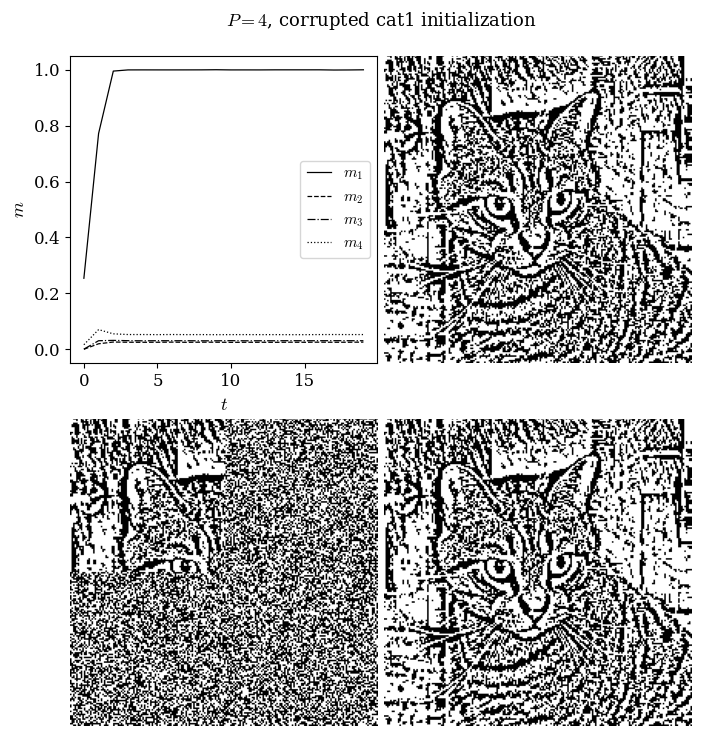

In [21]:
linestyles = ['-', '--', '-.', ':', (0, (1,1)), (0, (5,1)), (0, (3,1,1,1)), (0, (5,2,1,2))]

plt.gray()
fig, ((ax0, ax1), (ax2, ax3)) = plt.subplots(nrows=2, ncols=2, figsize=(12,12))
fig.suptitle('$P=4$, corrupted cat1 initialization')


for i in range(P):
  ax0.plot(m[:,i],label=rf'$m_{i+1}$',color='black',linestyle=linestyles[i % len(linestyles)])
ax0.set_xlabel('$t$')
ax0.set_ylabel('$m$')
ax0.legend(loc='center right')
ax0.set_box_aspect(1)   # square plot, as the images
ax1.imshow(bw[index])
ax1.axis("off")
ax2.imshow(bw0)
ax2.axis("off")
ax3.imshow(bwE)
ax3.axis("off")

plt.tight_layout()
save('P4_corrupted.pdf', FULL)
plt.show()

# Phase diagram

In [23]:
def Pscan(beta,Ps):
  index=0
  bw0 = np.random.choice([0,255], (L,L))
  for i in range(int(L/2)):
    for j in range(int(L/2)):
      bw0[i,j]=bw[index][i,j]

  mf=[]
  for P in Ps:
    print(P)
    bwP = bw[0:P]
    m, bwE = Hopfield_iter(bw0,bwP,beta,10)
    mf.append([imagedot(bwE,x) for x in bwP])
  return np.array([x[0] for x in mf])

In [24]:
np.random.seed(0)   # fixed seed: reproduces the run shown in the book
Ps=range(2,25,2)
mf15 = Pscan(1.5,Ps)
mf2 = Pscan(2,Ps)
mf4 = Pscan(4,Ps)

2
4
6
8
10
12
14
16
18
20
22
24
2
4
6
8
10
12
14
16
18
20
22
24
2
4
6
8
10
12
14
16
18
20
22
24


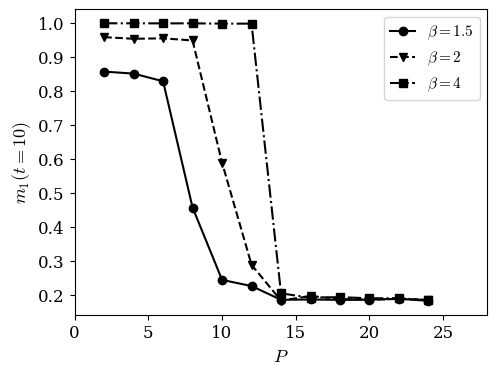

In [25]:
plt.plot(Ps,mf15,'o',label=r'$\beta=1.5$',color='black',linestyle='-')
plt.plot(Ps,mf2,'v',label=r'$\beta=2$',color='black',linestyle='--')
plt.plot(Ps,mf4,'s',label=r'$\beta=4$',color='black',linestyle='-.')
plt.legend(loc='upper right')
plt.xlabel('$P$')
plt.ylabel('$m_1(t=10)$')
plt.xlim((0,28))
plt.tight_layout()
save('mP.pdf', SINGLE)
plt.show()